Generated Dataset:
       Area  Bedrooms       Age      Price
0 -0.792521  0.504987 -0.114736  12.781276
1  0.280992 -0.208122 -0.622700 -21.876410
2  0.791032  1.402794 -0.909387  91.098757
3  0.625667 -1.070892 -0.857158 -82.265575
4 -0.342715 -0.161286 -0.802277 -30.416557

Dataset Shape: (100, 4)

Dataset saved successfully!

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Area      100 non-null    float64
 1   Bedrooms  100 non-null    float64
 2   Age       100 non-null    float64
 3   Price     100 non-null    float64
dtypes: float64(4)
memory usage: 3.3 KB
None

Statistical Summary:
             Area    Bedrooms         Age       Price
count  100.000000  100.000000  100.000000  100.000000
mean     0.091766    0.074822   -0.183233    5.939499
std      0.824799    1.112910    0.979100   82.967806
min     -1.952088   -2.619745   -3.241

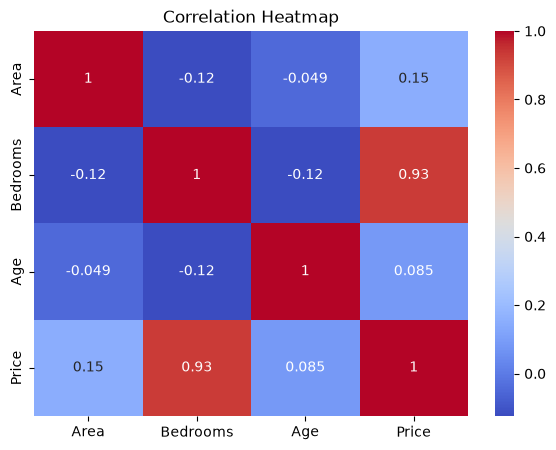


Training Data: (80, 3)
Testing Data: (20, 3)

Model Training Completed!

Intercept: 1.3037594527225016

Coefficients:
Area : 28.494751360770643
Bedrooms : 74.39534964608524
Age : 18.78132401431155

Actual vs Predicted:
    Actual Price  Predicted Price
0      21.857317         2.093189
1       2.797291         0.895999
2     -55.518053       -60.650777
3     -24.811083       -21.455254
4      44.742558        50.785549
5     299.270652       312.242546
6      46.214693        25.690872
7     -73.292895       -76.360439
8    -122.294898      -117.641896
9      12.781276        14.134881
10     42.295442        61.045734
11     33.693671        23.123316
12    -39.339121       -46.638800
13    -70.068434       -49.753283
14     16.225121        25.789765
15    -30.416557       -35.528542
16    -52.287633       -35.642430
17    -38.971474       -44.539903
18    -18.413697       -17.249954
19     66.693512        61.229934

Model Evaluation:
MAE: 8.960994532577917
MSE: 123.84680824798075


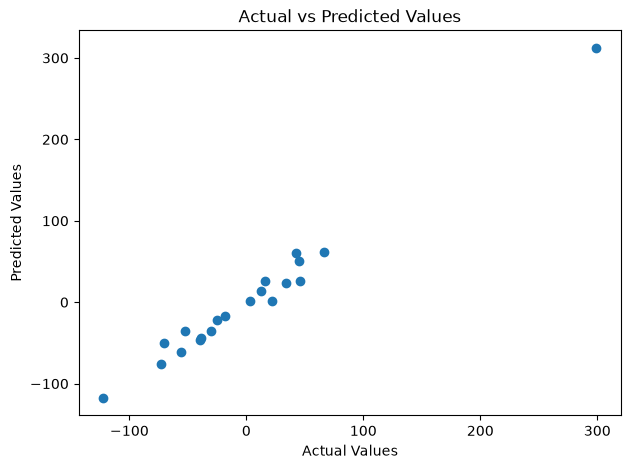


Predicted Value: 21.87327088228509


In [1]:
# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 2. Generate Synthetic Dataset Using Scikit-learn

X, y = make_regression(
    n_samples=100,
    n_features=3,
    n_informative=3,
    noise=10,
    random_state=42
)


# 3. Convert Dataset into DataFrame

df = pd.DataFrame(
    X,
    columns=["Area", "Bedrooms", "Age"]
)

df["Price"] = y

print("Generated Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)


# 4. Save Dataset as CSV

df.to_csv("house_data.csv", index=False)

print("\nDataset saved successfully!")


# 5. Explore Dataset

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


# 6. Correlation Analysis

correlation = df.corr()

print("\nCorrelation Matrix:")
print(correlation)

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


# 7. Separate Features and Target

X = df[["Area", "Bedrooms", "Age"]]
y = df["Price"]


# 8. Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# 9. Create Linear Regression Model

model = LinearRegression()


# 10. Train Model

model.fit(X_train, y_train)

print("\nModel Training Completed!")


# 11. Display Coefficients

print("\nIntercept:", model.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)


# 12. Predict Values

y_pred = model.predict(X_test)


# 13. Compare Actual and Predicted Values

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("\nActual vs Predicted:")
print(comparison)


# 14. Evaluate Model Performance

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


# 15. Visualize Actual vs Predicted Values

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")

plt.show()


# 16. Predict for New Data

new_data = pd.DataFrame({
    "Area": [1.5],
    "Bedrooms": [-0.5],
    "Age": [0.8]
})

prediction = model.predict(new_data)

print("\nPredicted Value:", prediction[0])